# Table 2 — Behaviour of statistical asymmetry for one-dimensional cellular automata

This notebook recomputes the classifications for all 88 elementary
cellular automaton rules listed in Table 2. Each rule starts from the
100-cell initial state used in Figure 2, generated with NumPy's
`RandomState(55)`. In each behaviour pair, the first label refers to
cyclic translations and the second to reflection.

`T` denotes an identically zero score, `C` a constant nonzero score,
`P2` a period of two, and `PF` a longer finite period. `PI` indicates
that the procedure detected no period in the observation window.

The simulation records 20000 states per rule, including the initial
state. The standard classification uses the final 2000 scores and
requires at least three cycles in that window. For Rules 54 and 73,
the code measures the asymmetry periods over a complete configuration
cycle, which can detect periods longer than the standard search allows.

The table below includes the recomputed classifications for Rules 25,
58, and 62. The [README errata](../README.md#errata) lists the changes
from the published table.

In [1]:
from textwrap import wrap
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import entropy

In [2]:
def hamming(x, y):
    return np.count_nonzero(x!=y)   

def translations(array):
    x = np.asarray(array)
    m = len(x)//2 + 1
    k = np.zeros(m)
    
    for i in range(m):
        ss = np.roll(x, i)
        k[i] = hamming(x, ss)

    return k, m

def reflections(array):
    x = np.asarray(array)
    y = x[::-1]
    
    return np.asarray([0, hamming(x,y)]), 2

def disc_dist(sequence):
    
    d = set(sequence)
    m = len(d)
    
    pk = np.zeros(m)
    for i in range(m):
        pk[i] = list(sequence).count(list(d)[i])
    
    return pk/sum(pk)
    
# Scaled by maximum distance
def sA(x, group):
    s = group(x)
    d1 = s[0]
    p1 = disc_dist(d1)
    n1 = s[1]
    e1 = entropy(p1)/np.log(n1)
    
    return e1*np.max(d1)/len(x.flatten())

In [3]:
def rule_index(triplet):
    L, C, R = triplet
    index = 7 - (4*L + 2*C + R)
    return int(index)

def CA_run(initial_state, n_steps, rule_number):
    rule_string = np.binary_repr(rule_number, 8)
    rule = np.array([int(bit) for bit in rule_string])

    m_cells = len(initial_state)
    CA_run = np.zeros((n_steps, m_cells))
    CA_run[0, :] = initial_state

    for step in range(1, n_steps):
        all_triplets = np.stack(
            [
                np.roll(CA_run[step - 1, :], 1),
                CA_run[step - 1, :],
                np.roll(CA_run[step - 1, :], -1),
            ]
        )
        CA_run[step, :] = rule[np.apply_along_axis(rule_index, 0, all_triplets)]

    return CA_run

def CA_complexity(initial_state, time_steps, rule, group):
    config = CA_run(initial_state, time_steps, rule)
    c = []
    for s in config:
        c += [sA(s, group)]
    
    return c

In [4]:
def classify_tail(scores, *, atol=1e-12):
    if np.allclose(scores, 0.0, rtol=0, atol=atol):
        return "T", 1

    if np.allclose(scores, scores[0], rtol=0, atol=atol):
        return "C", 1

    for period in range(2, len(scores) // 3 + 1):
        if np.allclose(scores[period:], scores[:-period], rtol=0, atol=atol):
            return ("P2" if period == 2 else "PF"), period

    return "PI", None


initial_state = np.random.RandomState(55).randint(0, 2, 100)
total_states = 20_000
tail_length = 2_000

published_groups = {
    ("T", "T"): (0, 8, 32, 40, 128, 136, 160, 168),
    ("C", "C"): (
        4, 12, 13, 19, 23, 36, 44, 50, 51, 57, 58, 72, 76, 77, 78, 104,
        132, 140, 164, 172, 178, 200, 204, 232,
    ),
    ("C", "PF"): (
        2, 10, 11, 14, 15, 24, 25, 34, 42, 43, 46, 56, 130, 138, 142,
        152, 162, 170, 184,
    ),
    ("P2", "C"): (28, 37),
    ("P2", "P2"): (1, 5, 29, 33, 94, 108, 156),
    ("P2", "PF"): (3, 6, 7, 9, 27, 35, 38, 62, 74, 134),
    ("PI", "PI"): (18, 22, 30, 45, 60, 90, 105, 106, 122, 126, 146, 150),
    ("PF", "PF"): (26, 41, 54, 73, 110, 154),
}

In [5]:
def find_configuration_cycle(trajectory):
    first_seen = {}
    for index, state in enumerate(trajectory):
        key = state.tobytes()
        if key in first_seen:
            return first_seen[key], index
        first_seen[key] = index
    raise ValueError("No repeated configuration in the recorded trajectory")


def cycle_score_period(scores, *, atol=1e-12):
    cycle_length = len(scores)
    for period in range(1, cycle_length + 1):
        if cycle_length % period == 0 and np.allclose(
            scores, np.roll(scores, period), rtol=0, atol=atol
        ):
            return period

In [6]:
rules = sorted(rule for group in published_groups.values() for rule in group)
assert len(rules) == len(set(rules)) == 88

groups = {behaviour: [] for behaviour in published_groups}

for rule in rules:
    trajectory = CA_run(initial_state.copy(), total_states, rule)

    if rule in (54, 73):
        start, stop = find_configuration_cycle(trajectory)
        states = trajectory[start:stop]
    else:
        states = trajectory[-tail_length:]

    labels = []
    for transform in (translations, reflections):
        scores = np.array([sA(state, transform) for state in states])

        if rule in (54, 73):
            period = cycle_score_period(scores)
            if period is None:
                raise RuntimeError(f"No asymmetry period found for rule {rule}")
            label = classify_tail(scores)[0] if period <= 2 else "PF"
        else:
            label, _ = classify_tail(scores)

        labels.append(label)

    groups.setdefault(tuple(labels), []).append(rule)

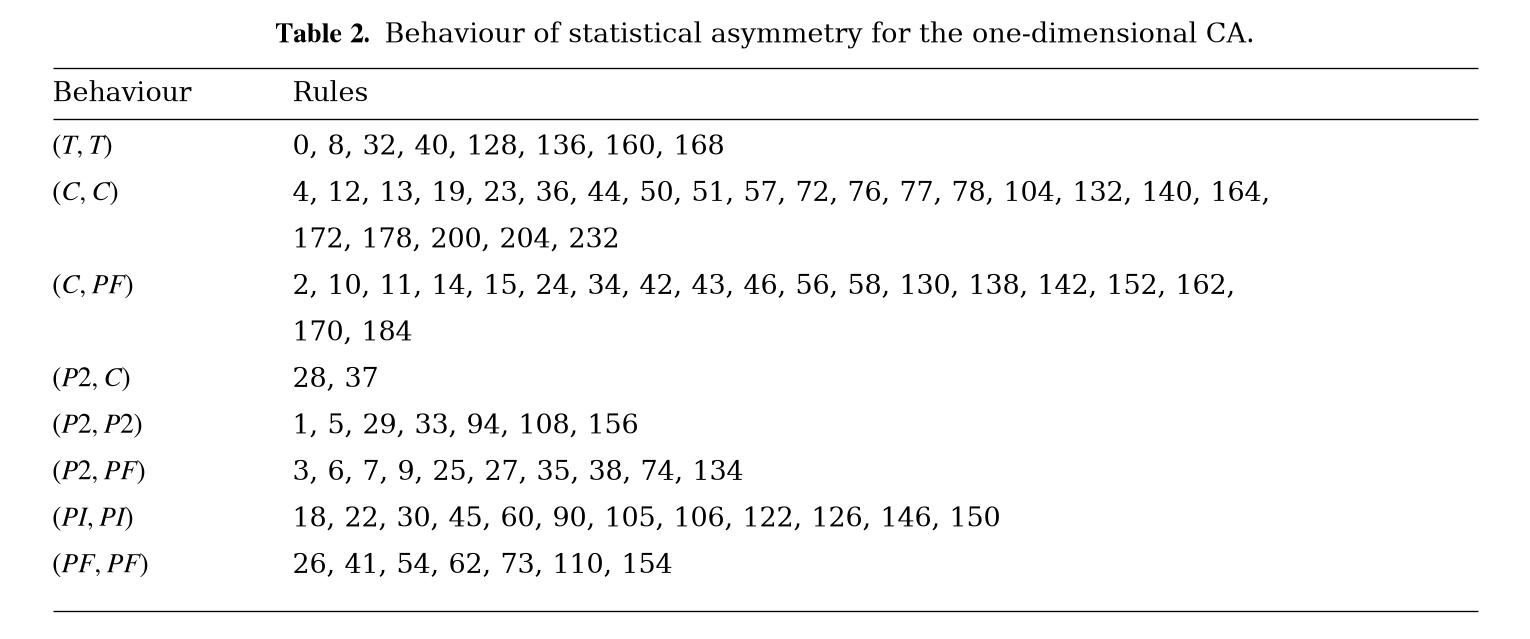

In [7]:
table_rows = [
    (behaviour, wrap(", ".join(map(str, members)), width=75))
    for behaviour, members in groups.items()
    if members
]

line_count = sum(len(lines) for _, lines in table_rows)
height = line_count + 3.1

with plt.rc_context({"font.family": "serif", "mathtext.fontset": "stix"}):
    fig, ax = plt.subplots(figsize=(10, 0.31 * height), dpi=150)
    fig.patch.set_facecolor("white")
    ax.set_xlim(0, 10)
    ax.set_ylim(0, height)
    ax.axis("off")

    ax.text(
        5, height - 0.45,
        r"$\mathbf{Table\ 2.}$ Behaviour of statistical asymmetry "
        "for the one-dimensional CA.",
        ha="center", va="center", fontsize=13, color="black",
    )

    left, rules_x, right = 0.25, 1.85, 9.75
    ax.hlines(
        [height - 1.15, height - 2.25, 0.28],
        left, right, color="black", linewidth=0.65,
    )
    ax.text(left, height - 1.70, "Behaviour", va="center", fontsize=13, color="black")
    ax.text(rules_x, height - 1.70, "Rules", va="center", fontsize=13, color="black")

    y = height - 2.85
    for (translation, reflection), lines in table_rows:
        ax.text(
            left, y, rf"$({translation}, {reflection})$",
            va="center", fontsize=13, color="black",
        )
        for line in lines:
            ax.text(rules_x, y, line, va="center", fontsize=13, color="black")
            y -= 1

    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    plt.show()